In [4]:
# 1. Khai báo các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 2. Nhập dữ liệu (Thay thế đường dẫn bằng file của bạn)
# Ví dụ: df = pd.read_csv('du_lieu_cua_ban.csv')

print("Đã khai báo xong các thư viện chuẩn bị cho mô hình Linear Regression!")

Đã khai báo xong các thư viện chuẩn bị cho mô hình Linear Regression!


In [5]:
import os
import pandas as pd

def load_dataset(name: str, path: str) -> pd.DataFrame:
    """Nạp dữ liệu từ file CSV, kiểm tra sự tồn tại của file và in thông tin cơ bản."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Lỗi: Không tìm thấy file {name} tại đường dẫn: {path}")
    
    df = pd.read_csv(path)
    print(f"-> Đã tải xong {name}: {df.shape[0]} dòng, {df.shape[1]} cột.")
    return df

# 1. Khai báo đường dẫn tới các tập Train, Val, Test
train_path = r"D:\File Code\Testing model\data\smartphones_train_clean.csv"
val_path = r"D:\File Code\Testing model\data\smartphones_val_clean.csv"
test_path = r"D:\File Code\Testing model\data\smartphones_test_clean.csv"

# 2. Thực hiện tải dữ liệu
df_train = load_dataset("TRAIN", train_path)
df_val = load_dataset("VALIDATION", val_path)
df_test = load_dataset("TEST", test_path)

print("\n--- ĐÃ NẠP THÀNH CÔNG 3 TẬP DỮ LIỆU ---")
print(f"Tập Train: {df_train.shape}")
print(f"Tập Val:   {df_val.shape}")
print(f"Tập Test:  {df_test.shape}")

-> Đã tải xong TRAIN: 1337 dòng, 21 cột.
-> Đã tải xong VALIDATION: 286 dòng, 21 cột.
-> Đã tải xong TEST: 287 dòng, 21 cột.

--- ĐÃ NẠP THÀNH CÔNG 3 TẬP DỮ LIỆU ---
Tập Train: (1337, 21)
Tập Val:   (286, 21)
Tập Test:  (287, 21)


In [6]:
# Kiểm tra thông tin tổng quan về các cột, kiểu dữ liệu và số lượng giá trị phi rỗng (non-null)
print("--- THÔNG TIN DỮ LIỆU ---")
df_train.info()

# Kiểm tra số lượng giá trị bị thiếu (NaN) ở mỗi cột
print("\n--- SỐ LƯỢNG GIÁ TRỊ THIẾU (NaN) TRÊN MỖI CỘT ---")
print(df_train.isnull().sum())

# Thống kê mô tả đối với các cột số
print("\n--- THỐNG KÊ MÔ TẢ CÁC CỘT SỐ ---")
display(df_train.describe())

--- THÔNG TIN DỮ LIỆU ---
<class 'pandas.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hãng Sản Xuất                     1337 non-null   str    
 1   Giá Bán (EUR)                     1337 non-null   float64
 2   RAM (GB)                          1337 non-null   float64
 3   ROM (GB)                          1337 non-null   float64
 4   Kích Thước Màn Hình (inch)        1337 non-null   float64
 5   Tỷ Lệ Màn Hình (%)                1337 non-null   float64
 6   Tấm Nền Màn Hình                  1337 non-null   str    
 7   Camera Sau (MP)                   1337 non-null   float64
 8   Camera Trước (MP)                 1337 non-null   float64
 9   Dung Lượng Pin (mAh)              1337 non-null   float64
 10  Thiết Kế Pin                      1337 non-null   str    
 11  Độ Dày (mm)                       1337 non-null   floa

,Giá Bán (EUR),RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Độ Dày (mm),Trọng Lượng (g),Số Nhân CPU (Core),Xung Nhịp CPU (GHz),Năm Ra Mắt,NFC_Clean,Độ Phân Giải Đường Chéo (Pixels)
count,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000
mean,232.513089,1.847607,22.184667,5.051137,66.565744,9.998803,3.818025,2565.137622,9.073972,157.493418,4.627524,1.486761,2014.270007,0.317128,1573.043769
std,136.967138,1.017488,26.405151,0.762333,6.289098,4.443367,3.352262,790.884127,1.709163,42.176233,2.259131,0.389513,1.634565,0.465532,567.670958
min,40.000000,1.000000,1.000000,3.000000,22.800000,0.300000,0.000000,1000.000000,4.900000,88.200000,1.000000,0.400000,2007.000000,0.000000,400.000000
25%,140.000000,1.000000,8.000000,4.650000,64.200000,8.000000,1.300000,2000.000000,8.000000,138.900000,4.000000,1.200000,2013.000000,0.000000,1101.453585
50%,200.000000,1.750000,16.000000,5.000000,67.500000,8.000000,2.100000,2470.000000,8.900000,149.000000,4.000000,1.400000,2014.000000,0.000000,1468.604780
75%,280.000000,2.000000,32.000000,5.500000,70.600000,13.000000,5.000000,3000.000000,9.800000,164.000000,8.000000,1.700000,2015.000000,1.000000,2202.907170
max,1400.000000,8.000000,256.000000,8.000000,93.200000,41.000000,20.000000,7000.000000,21.100000,480.000000,10.000000,2.700000,2017.000000,1.000000,4405.814340


In [7]:
import pandas as pd

# Xác định cột mục tiêu và các đặc trưng phân loại
target_col = 'Giá Bán (EUR)'
object_cols = df_train.select_dtypes(include=['object']).columns.tolist()

print(f"Các biến phân loại cần One-Hot Encoding: {object_cols}")

# Thực hiện One-Hot Encoding tách biệt các biến đặc trưng (X) và biến mục tiêu (y)
y_train = df_train[target_col]
y_val = df_val[target_col]
y_test = df_test[target_col]

X_train_raw = df_train.drop(columns=[target_col])
X_val_raw = df_val.drop(columns=[target_col])
X_test_raw = df_test.drop(columns=[target_col])

# Áp dụng pd.get_dummies
X_train_encoded = pd.get_dummies(X_train_raw, columns=object_cols, drop_first=True)
X_val_encoded = pd.get_dummies(X_val_raw, columns=object_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_raw, columns=object_cols, drop_first=True)

# Đồng bộ hóa cấu trúc cột giữa các tập dữ liệu để đảm bảo mô hình nhận đúng định dạng đầu vào
X_train, X_val = X_train_encoded.align(X_val_encoded, join='left', axis=1, fill_value=0)
X_train, X_test = X_train.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Chuyển đổi các cột boolean sang kiểu int (0/1)
X_train = X_train.astype(float)
X_val = X_val.astype(float)
X_test = X_test.astype(float)

print("\n--- THÔNG TIN KÍCH THƯỚC SAU KHI MÃ HÓA ONE-HOT ---")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

Các biến phân loại cần One-Hot Encoding: ['Hãng Sản Xuất', 'Tấm Nền Màn Hình', 'Thiết Kế Pin', 'Cảm Biến Vân Tay', 'Hỗ Trợ Mạng', 'Hãng Chip']

--- THÔNG TIN KÍCH THƯỚC SAU KHI MÃ HÓA ONE-HOT ---
X_train shape: (1337, 90)
X_val shape:   (286, 90)
X_test shape:  (287, 90)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10776\3012938872.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df_train.select_dtypes(include=['object']).columns.tolist()


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Khởi tạo và huấn luyện mô hình Baseline Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Dự đoán trên tập Train và Validation
y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

# Đánh giá hiệu suất
def evaluate_predictions(y_true, y_pred, dataset_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP {dataset_name.upper()} ===")
    print(f"MAE : {mae:.4f} EUR")
    print(f"RMSE: {rmse:.4f} EUR")
    print(f"R²  : {r2:.4f}\n")

evaluate_predictions(y_train, y_train_pred, "Train")
evaluate_predictions(y_val, y_val_pred, "Validation")

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN ===
MAE : 48.2245 EUR
RMSE: 71.1959 EUR
R²  : 0.7296

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ===
MAE : 58.1961 EUR
RMSE: 86.2328 EUR
R²  : 0.6154



### 1. Tạo các Đặc trưng Vật lý và Hiệu năng Kỹ thuật
Để giúp các mô hình học máy (nhất là mô hình baseline tuyến tính) nắm bắt được các mối quan hệ phi tuyến phức tạp trong thế giới thực, chúng ta sẽ kết hợp các thông số phần cứng rời rạc thành các chỉ số mang ý nghĩa vật lý và kinh tế cụ thể:
* **Mật độ điểm ảnh (PPI)**: Đo lường độ sắc nét thực tế của màn hình dựa trên độ phân giải đường chéo và kích thước vật lý thay vì chỉ nhìn vào số inch đơn thuần.
* **Tối ưu thiết kế pin (Tỉ số Pin/Độ Dày)**: Chỉ số thể hiện trình độ gia công và phân khúc cao cấp của máy (thiết bị mỏng nhưng vẫn tối ưu được dung lượng pin lớn).
* **Năng lực xử lý thô (Tổng Xung Nhịp)**: Phản ánh trực tiếp sức mạnh xử lý tối đa của CPU bằng cách nhân số nhân (Cores) với xung nhịp đơn nhân.
* **Chỉ số hiệu năng tổng thể**: Kết hợp dung lượng RAM vật lý với tổng xung nhịp CPU nhằm tạo ra biến ước lượng sức mạnh vận hành đa nhiệm thực tế.
* **Tổng camera (Tổng MP Camera)**: Tính tổng số Megapixel của cả camera trước và camera sau để đại diện cho mức độ đầu tư vào tính năng nhiếp ảnh trên thiết bị.

In [9]:
def create_engineered_features(df):
    # Tạo bản sao để tránh chỉnh sửa trực tiếp trên DataFrame gốc
    df_feat = df.copy()

    # 1. Mật độ điểm ảnh (PPI)
    df_feat['PPI'] = df_feat['Độ Phân Giải Đường Chéo (Pixels)'] / df_feat['Kích Thước Màn Hình (inch)']

    # 2. Tối ưu thiết kế pin (Tỷ số Pin/Độ Dày)
    df_feat['Tỉ số Pin/Độ Dày'] = df_feat['Dung Lượng Pin (mAh)'] / df_feat['Độ Dày (mm)']

    # 3. Năng lực xử lý thô (Tổng Xung Nhịp)
    df_feat['Tổng Xung Nhịp'] = df_feat['Số Nhân CPU (Core)'] * df_feat['Xung Nhịp CPU (GHz)']

    # 4. Chỉ số hiệu năng tổng thể
    df_feat['Chỉ Số Hiệu Năng'] = df_feat['RAM (GB)'] * df_feat['Tổng Xung Nhịp']

    # 5. Tổng camera
    df_feat['Tổng MP Camera'] = df_feat['Camera Sau (MP)'] + df_feat['Camera Trước (MP)']

    return df_feat

# Áp dụng tạo đặc trưng mới cho cả 3 tập dữ liệu
df_train_feat = create_engineered_features(df_train)
df_val_feat = create_engineered_features(df_val)
df_test_feat = create_engineered_features(df_test)

print("--- ĐÃ BỔ SUNG 5 ĐẶC TRƯNG MỚI THÀNH CÔNG ---")
display(df_train_feat[['PPI', 'Tỉ số Pin/Độ Dày', 'Tổng Xung Nhịp', 'Chỉ Số Hiệu Năng', 'Tổng MP Camera']].head())

--- ĐÃ BỔ SUNG 5 ĐẶC TRƯNG MỚI THÀNH CÔNG ---


,PPI,Tỉ số Pin/Độ Dày,Tổng Xung Nhịp,Chỉ Số Hiệu Năng,Tổng MP Camera
0,489.534927,364.583333,16.0,48.0,32.0
1,293.720956,275.000000,5.0,10.0,18.0
2,283.019434,329.333333,9.2,18.4,6.2
3,440.581434,285.714286,9.2,18.4,15.0
4,293.720956,518.987342,11.2,33.6,18.0


In [10]:
# Tách đặc trưng (X) và biến mục tiêu (y) mới
y_train_f = df_train_feat[target_col]
y_val_f = df_val_feat[target_col]
y_test_f = df_test_feat[target_col]

X_train_raw_f = df_train_feat.drop(columns=[target_col])
X_val_raw_f = df_val_feat.drop(columns=[target_col])
X_test_raw_f = df_test_feat.drop(columns=[target_col])

# Thực hiện One-Hot Encoding trên tập dữ liệu đã có đặc trưng mới
X_train_encoded_f = pd.get_dummies(X_train_raw_f, columns=object_cols, drop_first=True)
X_val_encoded_f = pd.get_dummies(X_val_raw_f, columns=object_cols, drop_first=True)
X_test_encoded_f = pd.get_dummies(X_test_raw_f, columns=object_cols, drop_first=True)

# Đồng bộ hóa cấu trúc cột giữa các tập dữ liệu
X_train_f, X_val_f = X_train_encoded_f.align(X_val_encoded_f, join='left', axis=1, fill_value=0)
X_train_f, X_test_f = X_train_f.align(X_test_encoded_f, join='left', axis=1, fill_value=0)

# Chuyển đổi các cột sang kiểu float
X_train_f = X_train_f.astype(float)
X_val_f = X_val_f.astype(float)
X_test_f = X_test_f.astype(float)

print(f"Kích thước tập huấn luyện mới: {X_train_f.shape}")

Kích thước tập huấn luyện mới: (1337, 95)


In [11]:
# Huấn luyện lại mô hình Baseline Linear Regression với các đặc trưng mới
lr_model_f = LinearRegression()
lr_model_f.fit(X_train_f, y_train_f)

# Dự đoán
y_train_pred_f = lr_model_f.predict(X_train_f)
y_val_pred_f = lr_model_f.predict(X_val_f)

# Đánh giá
print("=== KẾT QUẢ VỚI CÁC ĐẶC TRƯNG MỚI THÊM VÀO ===")
evaluate_predictions(y_train_f, y_train_pred_f, "Train (Mới)")
evaluate_predictions(y_val_f, y_val_pred_f, "Validation (Mới)")

=== KẾT QUẢ VỚI CÁC ĐẶC TRƯNG MỚI THÊM VÀO ===
=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN (MỚI) ===
MAE : 47.5849 EUR
RMSE: 69.1382 EUR
R²  : 0.7450

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (MỚI) ===
MAE : 56.7385 EUR
RMSE: 83.9240 EUR
R²  : 0.6357



### 2. Chuẩn hóa Đặc trưng theo Dòng chảy Thời gian (Định luật Moore)
Dữ liệu điện thoại trải dài từ năm 2007 đến năm 2017, giai đoạn mà công nghệ bán dẫn và phần cứng di động phát triển cực kỳ vũ bão theo định luật Moore. Một cấu hình là siêu phẩm siêu đắt đỏ ở năm 2011 (như 1 GB RAM) có thể đã trở thành rác công nghệ giá rẻ ở năm 2016.

Để mô hình phân biệt được phân khúc định vị của thiết bị **ngay tại thời điểm nó ra mắt**, chúng ta thực hiện kỹ thuật sau:
1. Tính toán cấu hình trung bình (`RAM (GB)`, `ROM (GB)`, `Tổng MP Camera`) theo từng năm dựa trên dữ liệu lịch sử của tập **Train** (tránh rò rỉ thông tin từ tập Validation/Test).
2. Tạo các tỉ số so sánh tương đối: `RAM_So_Voi_Nam`, `ROM_So_Voi_Nam`, `Cam_So_Voi_Nam` bằng cách chia thông số thực tế cho mức trung bình của năm đó.

Nhờ vậy, một chiếc điện thoại có RAM cao vượt trội so với trung bình năm ra mắt sẽ được mô hình nhận diện chính xác là dòng Flagship cao cấp bất kể thời kỳ nào.

In [12]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# --- CHUẨN BỊ ĐẶC TRƯNG ĐỘC LẬP (CHỈ DÙNG DỮ LIỆU GỐC) ---
# Để tính 'Tổng MP Camera' độc lập phục vụ định luật Moore, ta tạo cột tạm từ df_train gốc
temp_train = df_train.copy()
temp_train['Tổng MP Camera'] = temp_train['Camera Sau (MP)'] + temp_train['Camera Trước (MP)']

# 1. Tính giá trị trung bình theo năm dựa trên tập Train gốc
year_stats = temp_train.groupby('Năm Ra Mắt').agg(
    mean_ram=('RAM (GB)', 'mean'),
    mean_rom=('ROM (GB)', 'mean'),
    mean_cam=('Tổng MP Camera', 'mean')
).reset_index()

# Thống kê toàn cục dự phòng
global_ram_mean = df_train['RAM (GB)'].mean()
global_rom_mean = df_train['ROM (GB)'].mean()
global_cam_mean = temp_train['Tổng MP Camera'].mean()

def add_relative_features_only(df_raw, stats):
    df_feat = df_raw.copy()
    # Tạo cột phụ để chia tỉ lệ
    df_feat['Tổng MP Camera'] = df_feat['Camera Sau (MP)'] + df_feat['Camera Trước (MP)']

    # Gộp dữ liệu trung bình năm
    df_merged = df_feat.merge(stats, on='Năm Ra Mắt', how='left')

    # Điền giá trị trống bằng giá trị trung bình toàn cục
    df_merged['mean_ram'] = df_merged['mean_ram'].fillna(global_ram_mean)
    df_merged['mean_rom'] = df_merged['mean_rom'].fillna(global_rom_mean)
    df_merged['mean_cam'] = df_merged['mean_cam'].fillna(global_cam_mean)

    # Tạo 3 đặc trưng định luật Moore
    df_merged['RAM_So_Voi_Nam'] = df_merged['RAM (GB)'] / df_merged['mean_ram']
    df_merged['ROM_So_Voi_Nam'] = df_merged['ROM (GB)'] / df_merged['mean_rom']
    df_merged['Cam_So_Voi_Nam'] = df_merged['Tổng MP Camera'] / df_merged['mean_cam']

    # Xóa bỏ các cột phụ và cột trung bình tạm thời để đảm bảo ĐỘC LẬP hoàn toàn
    df_merged = df_merged.drop(columns=['mean_ram', 'mean_rom', 'mean_cam', 'Tổng MP Camera'])
    return df_merged

# 2. Tạo tập dữ liệu chỉ chứa đặc trưng định luật Moore (không chứa đặc trưng ở phần 1)
df_train_rel = add_relative_features_only(df_train, year_stats)
df_val_rel = add_relative_features_only(df_val, year_stats)
df_test_rel = add_relative_features_only(df_test, year_stats)

# 3. Phân tách đặc trưng đầu vào và nhãn mục tiêu
y_train_r = df_train_rel[target_col]
y_val_r = df_val_rel[target_col]
y_test_r = df_test_rel[target_col]

X_train_raw_r = df_train_rel.drop(columns=[target_col])
X_val_raw_r = df_val_rel.drop(columns=[target_col])
X_test_raw_r = df_test_rel.drop(columns=[target_col])

# 4. Mã hóa One-hot & Căn chỉnh cột
X_train_encoded_r = pd.get_dummies(X_train_raw_r, columns=object_cols, drop_first=True)
X_val_encoded_r = pd.get_dummies(X_val_raw_r, columns=object_cols, drop_first=True)
X_test_encoded_r = pd.get_dummies(X_test_raw_r, columns=object_cols, drop_first=True)

X_train_r = X_train_encoded_r.astype(float)
X_val_r = X_val_encoded_r.reindex(columns=X_train_r.columns, fill_value=0).astype(float)
X_test_r = X_test_encoded_r.reindex(columns=X_train_r.columns, fill_value=0).astype(float)

# 5. Huấn luyện mô hình Linear Regression
lr_model_r = LinearRegression()
lr_model_r.fit(X_train_r, y_train_r)

y_train_pred_r = lr_model_r.predict(X_train_r)
y_val_pred_r = lr_model_r.predict(X_val_r)

print("=== KẾT QUẢ MÔ HÌNH ĐỘC LẬP: CHỈ SỬ DỤNG ĐẶC TRƯNG ĐỊNH LUẬT MOORE ===")
evaluate_predictions(y_train_r, y_train_pred_r, "Train (Chỉ đặc trưng thời gian)")
evaluate_predictions(y_val_r, y_val_pred_r, "Validation (Chỉ đặc trưng thời gian)")

=== KẾT QUẢ MÔ HÌNH ĐỘC LẬP: CHỈ SỬ DỤNG ĐẶC TRƯNG ĐỊNH LUẬT MOORE ===
=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN (CHỈ ĐẶC TRƯNG THỜI GIAN) ===
MAE : 47.3858 EUR
RMSE: 70.1169 EUR
R²  : 0.7377

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (CHỈ ĐẶC TRƯNG THỜI GIAN) ===
MAE : 59.5717 EUR
RMSE: 93.8822 EUR
R²  : 0.5441



### 3. Đánh giá Mô hình Gộp đồng thời cả 2 phương pháp Feature Engineering

Chúng ta tiến hành tạo đồng thời cả đặc trưng kỹ thuật vật lý lẫn đặc trưng chuẩn hóa theo dòng chảy thời gian (Định luật Moore) trên nền dữ liệu gốc ban đầu để xem sự kết hợp này cải thiện độ chính xác như thế nào.

In [13]:
# 1. Hàm tạo toàn bộ đặc trưng gộp hoàn toàn nhất quán
def create_fully_combined_features(df_raw, stats):
    df_feat = df_raw.copy()

    # Tạo các đặc trưng vật lý từ phần 1
    df_feat['PPI'] = df_feat['Độ Phân Giải Đường Chéo (Pixels)'] / df_feat['Kích Thước Màn Hình (inch)']
    df_feat['Tỉ số Pin/Độ Dày'] = df_feat['Dung Lượng Pin (mAh)'] / df_feat['Độ Dày (mm)']
    df_feat['Tổng Xung Nhịp'] = df_feat['Số Nhân CPU (Core)'] * df_feat['Xung Nhịp CPU (GHz)']
    df_feat['Chỉ Số Hiệu Năng'] = df_feat['RAM (GB)'] * df_feat['Tổng Xung Nhịp']
    df_feat['Tổng MP Camera'] = df_feat['Camera Sau (MP)'] + df_feat['Camera Trước (MP)']

    # Gộp dữ liệu trung bình năm từ Train
    df_merged = df_feat.merge(stats, on='Năm Ra Mắt', how='left')

    # Xử lý giá trị trống dự phòng
    df_merged['mean_ram'] = df_merged['mean_ram'].fillna(global_ram_mean)
    df_merged['mean_rom'] = df_merged['mean_rom'].fillna(global_rom_mean)
    df_merged['mean_cam'] = df_merged['mean_cam'].fillna(global_cam_mean)

    # Tạo các đặc trưng tương đối theo định luật Moore từ phần 2
    df_merged['RAM_So_Voi_Nam'] = df_merged['RAM (GB)'] / df_merged['mean_ram']
    df_merged['ROM_So_Voi_Nam'] = df_merged['ROM (GB)'] / df_merged['mean_rom']
    df_merged['Cam_So_Voi_Nam'] = df_merged['Tổng MP Camera'] / df_merged['mean_cam']

    # Loại bỏ các cột trung bình tạm thời để dữ liệu gọn gàng
    df_merged = df_merged.drop(columns=['mean_ram', 'mean_rom', 'mean_cam'])
    return df_merged

# 2. Áp dụng tích hợp các đặc trưng cho cả 3 tập dữ liệu
df_train_comb = create_fully_combined_features(df_train, year_stats)
df_val_comb = create_fully_combined_features(df_val, year_stats)
df_test_comb = create_fully_combined_features(df_test, year_stats)

# 3. Phân tách biến độc lập X và biến mục tiêu y
y_train_comb = df_train_comb[target_col]
y_val_comb = df_val_comb[target_col]
y_test_comb = df_test_comb[target_col]

X_train_raw_comb = df_train_comb.drop(columns=[target_col])
X_val_raw_comb = df_val_comb.drop(columns=[target_col])
X_test_raw_comb = df_test_comb.drop(columns=[target_col])

# 4. Mã hóa One-hot & Căn chỉnh cột đồng bộ
X_train_encoded_comb = pd.get_dummies(X_train_raw_comb, columns=object_cols, drop_first=True)
X_val_encoded_comb = pd.get_dummies(X_val_raw_comb, columns=object_cols, drop_first=True)
X_test_encoded_comb = pd.get_dummies(X_test_raw_comb, columns=object_cols, drop_first=True)

X_train_comb_final = X_train_encoded_comb.astype(float)
X_val_comb_final = X_val_encoded_comb.reindex(columns=X_train_comb_final.columns, fill_value=0).astype(float)
X_test_comb_final = X_test_encoded_comb.reindex(columns=X_train_comb_final.columns, fill_value=0).astype(float)

print(f"Kích thước tập huấn luyện tích hợp đầy đủ đặc trưng gộp: {X_train_comb_final.shape}")

Kích thước tập huấn luyện tích hợp đầy đủ đặc trưng gộp: (1337, 98)


In [14]:
# 5. Huấn luyện và Đánh giá Baseline Linear Regression trên dữ liệu Gộp
lr_model_comb = LinearRegression()
lr_model_comb.fit(X_train_comb_final, y_train_comb)

y_train_pred_comb = lr_model_comb.predict(X_train_comb_final)
y_val_pred_comb = lr_model_comb.predict(X_val_comb_final)

print("=== KẾT QUẢ MÔ HÌNH VỚI TOÀN BỘ CÁC ĐẶC TRƯNG GỘP (VẬT LÝ + THỜI GIAN) ===")
evaluate_predictions(y_train_comb, y_train_pred_comb, "Train (Gộp)")
evaluate_predictions(y_val_comb, y_val_pred_comb, "Validation (Gộp)")

=== KẾT QUẢ MÔ HÌNH VỚI TOÀN BỘ CÁC ĐẶC TRƯNG GỘP (VẬT LÝ + THỜI GIAN) ===
=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN (GỘP) ===
MAE : 46.6527 EUR
RMSE: 68.3022 EUR
R²  : 0.7511

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (GỘP) ===
MAE : 58.0046 EUR
RMSE: 91.0453 EUR
R²  : 0.5712



### 4. Áp dụng Log Transformation và Feature Scaling cho Mô hình Gộp
Chúng ta tiến hành thực hiện đồng thời:
* Biến đổi logarit (`np.log1p`) cho biến `ROM (GB)` và biến mục tiêu `Giá Bán (EUR)`.
* Chuẩn hóa tất cả các biến số liên tục bằng `StandardScaler` (fit trên tập Train, transform cho tập Val và Test) để loại bỏ sự chênh lệch lớn về thang đo.

In [15]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Tạo bản sao từ dữ liệu gộp đầy đủ
X_train_scaled = X_train_comb_final.copy()
X_val_scaled = X_val_comb_final.copy()
X_test_scaled = X_test_comb_final.copy()

# 2. Áp dụng Log Transformation cho đặc trưng bị lệch (ROM)
if 'ROM (GB)' in X_train_scaled.columns:
    X_train_scaled['ROM (GB)'] = np.log1p(X_train_scaled['ROM (GB)'])
    X_val_scaled['ROM (GB)'] = np.log1p(X_val_scaled['ROM (GB)'])
    X_test_scaled['ROM (GB)'] = np.log1p(X_test_scaled['ROM (GB)'])

# Biến đổi logarit cho biến mục tiêu
y_train_log = np.log1p(y_train_comb)
y_val_log = np.log1p(y_val_comb)
y_test_log = np.log1p(y_test_comb)

# 3. Chuẩn hóa thang đo (StandardScaler) cho tất cả các biến số
numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Kích Thước Màn Hình (inch)', 'Tỷ Lệ Màn Hình (%)',
    'Camera Sau (MP)', 'Camera Trước (MP)', 'Dung Lượng Pin (mAh)', 'Độ Dày (mm)',
    'Trọng Lượng (g)', 'Số Nhân CPU (Core)', 'Xung Nhịp CPU (GHz)', 'Năm Ra Mắt',
    'Độ Phân Giải Đường Chéo (Pixels)', 'PPI', 'Tỉ số Pin/Độ Dày', 'Tổng Xung Nhịp',
    'Chỉ Số Hiệu Năng', 'Tổng MP Camera', 'RAM_So_Voi_Nam', 'ROM_So_Voi_Nam', 'Cam_So_Voi_Nam'
]

# Lọc các biến thực tế tồn tại trong tập dữ liệu
numeric_cols = [col for col in numeric_cols if col in X_train_scaled.columns]

scaler = StandardScaler()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val_scaled[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

print("Đã hoàn thành Log Transformation (ROM) và chuẩn hóa dữ liệu với StandardScaler!")

Đã hoàn thành Log Transformation (ROM) và chuẩn hóa dữ liệu với StandardScaler!


In [16]:
# 4. Huấn luyện lại mô hình hồi quy tuyến tính trên dữ liệu chuẩn hóa
lr_scaled_model = LinearRegression()
lr_scaled_model.fit(X_train_scaled, y_train_log)

# Dự đoán trên tập Train và Validation (đầu ra ở dạng Log)
y_train_pred_log = lr_scaled_model.predict(X_train_scaled)
y_val_pred_log = lr_scaled_model.predict(X_val_scaled)

# Chuyển ngược kết quả dự đoán về thang gốc (EUR) bằng hàm np.expm1
y_train_pred_original = np.expm1(y_train_pred_log)
y_val_pred_original = np.expm1(y_val_pred_log)

# 5. Đánh giá hiệu suất mô hình
print("=== KẾT QUẢ MÔ HÌNH SAU KHI LOG VÀ SCALING (GỘP ĐẶC TRƯNG) ===")
evaluate_predictions(y_train_comb, y_train_pred_original, "Train (Log & Scaled)")
evaluate_predictions(y_val_comb, y_val_pred_original, "Validation (Log & Scaled)")

=== KẾT QUẢ MÔ HÌNH SAU KHI LOG VÀ SCALING (GỘP ĐẶC TRƯNG) ===
=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN (LOG & SCALED) ===
MAE : 45.0996 EUR
RMSE: 69.1637 EUR
R²  : 0.7448

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (LOG & SCALED) ===
MAE : 56.4839 EUR
RMSE: 91.8134 EUR
R²  : 0.5640



### 5. Huấn luyện Mô hình ElasticNet để kiểm soát hiện tượng đa cộng tuyến
Do số lượng cột tăng lên đáng kể sau khi thực hiện Feature Engineering, hiện tượng đa cộng tuyến xảy ra khiến Linear Regression thông thường có thể bị quá khớp hoặc kém ổn định. Chúng ta áp dụng mô hình `ElasticNet` kết hợp cơ chế phạt L1 và L2 để tự động chuẩn hóa hệ số của các biến đặc trưng.

In [17]:
from sklearn.linear_model import ElasticNet

# Khởi tạo mô hình ElasticNet
# Mặc định alpha=1.0 (mức độ phạt) và l1_ratio=0.5 (cân bằng giữa L1 và L2)
elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42, max_iter=5000)

# Huấn luyện mô hình trên dữ liệu đã log và scale
elastic_model.fit(X_train_scaled, y_train_log)

# Dự đoán trên tập Train và Validation (dạng log)
y_train_pred_elastic_log = elastic_model.predict(X_train_scaled)
y_val_pred_elastic_log = elastic_model.predict(X_val_scaled)

# Chuyển đổi ngược về thang gốc (EUR)
y_train_pred_elastic = np.expm1(y_train_pred_elastic_log)
y_val_pred_elastic = np.expm1(y_val_pred_elastic_log)

# Đánh giá hiệu suất
print("=== KẾT QUẢ MÔ HÌNH ELASTICNET (GỘP ĐẶC TRƯNG + LOG & SCALED) ===")
evaluate_predictions(y_train_comb, y_train_pred_elastic, "Train (ElasticNet)")
evaluate_predictions(y_val_comb, y_val_pred_elastic, "Validation (ElasticNet)")

=== KẾT QUẢ MÔ HÌNH ELASTICNET (GỘP ĐẶC TRƯNG + LOG & SCALED) ===
=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TRAIN (ELASTICNET) ===
MAE : 63.4189 EUR
RMSE: 96.0894 EUR
R²  : 0.5075

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (ELASTICNET) ===
MAE : 63.6938 EUR
RMSE: 98.8671 EUR
R²  : 0.4944



### 6. Thử nghiệm nhiều giá trị alpha và l1_ratio (Tuning ElasticNet) & Trực quan hóa kết quả
Chúng ta tiến hành thiết lập một lưới các tham số `alpha` và `l1_ratio` để tìm ra tổ hợp tối ưu giúp tối thiểu hóa RMSE trên tập Validation.

=== BỘ THAM SỐ TỐI ƯU NHẤT CHO MAE ===
Alpha: 0.001
L1 Ratio: 0.3
Validation MAE thấp nhất: 52.2349 EUR
Validation RMSE tương ứng: 80.9100 EUR


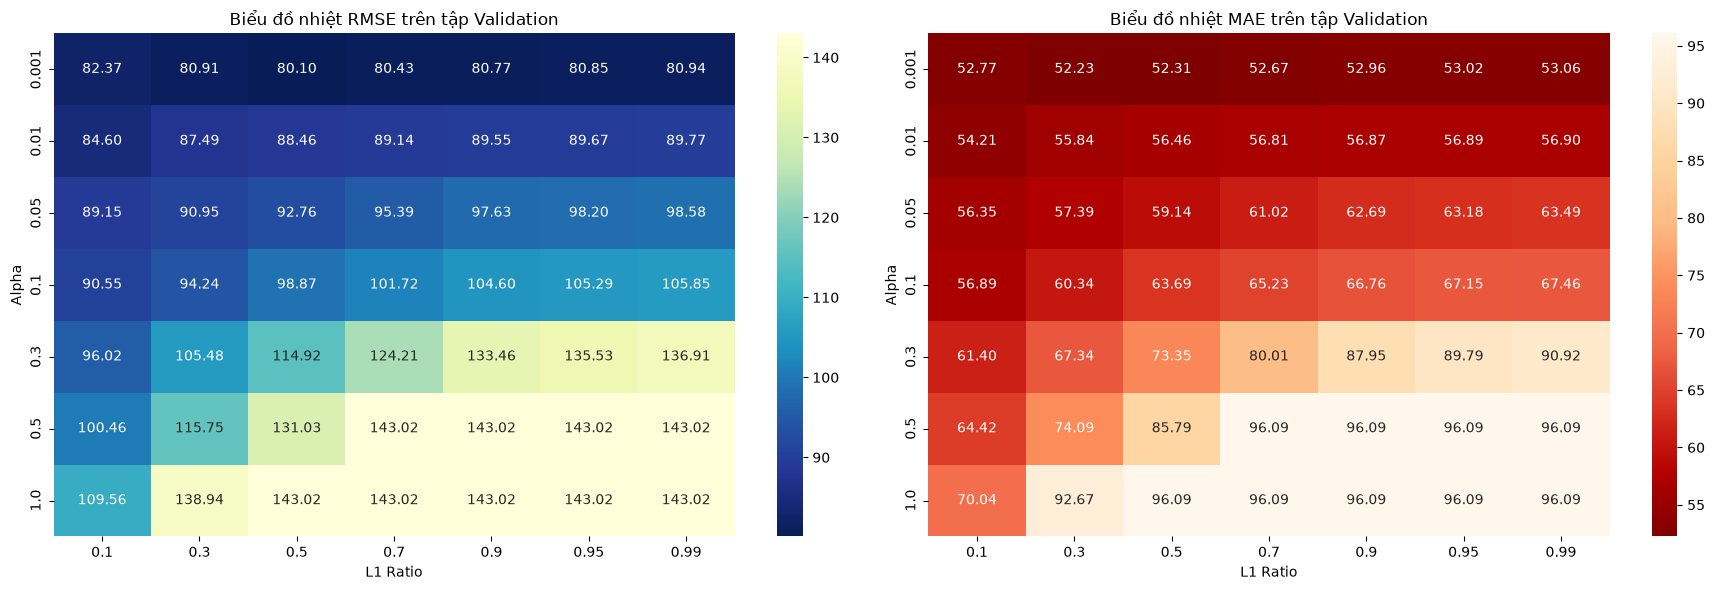

In [18]:
from sklearn.metrics import mean_absolute_error

# Thiết lập lưới tham số thử nghiệm tương tự
alphas = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

results_with_mae = []

for alpha in alphas:
    for l1_ratio in l1_ratios:
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42, max_iter=10000)
        model.fit(X_train_scaled, y_train_log)

        # Dự đoán trên tập Validation và đưa về thang đo gốc
        y_val_pred_log = model.predict(X_val_scaled)
        y_val_pred_orig = np.expm1(y_val_pred_log)

        # Tính toán cả RMSE và MAE
        val_rmse = np.sqrt(mean_squared_error(y_val_comb, y_val_pred_orig))
        val_mae = mean_absolute_error(y_val_comb, y_val_pred_orig)

        results_with_mae.append({
            'alpha': alpha,
            'l1_ratio': l1_ratio,
            'Validation RMSE': val_rmse,
            'Validation MAE': val_mae
        })

df_results_mae = pd.DataFrame(results_with_mae)

# Tìm bộ tham số tối ưu nhất cho MAE
best_mae_idx = df_results_mae['Validation MAE'].idxmin()
best_mae_param = df_results_mae.loc[best_mae_idx]

print("=== BỘ THAM SỐ TỐI ƯU NHẤT CHO MAE ===")
print(f"Alpha: {best_mae_param['alpha']}")
print(f"L1 Ratio: {best_mae_param['l1_ratio']}")
print(f"Validation MAE thấp nhất: {best_mae_param['Validation MAE']:.4f} EUR")
print(f"Validation RMSE tương ứng: {best_mae_param['Validation RMSE']:.4f} EUR")

# Vẽ biểu đồ nhiệt (Heatmap) so sánh RMSE và MAE bên cạnh nhau
pivot_rmse = df_results_mae.pivot(index='alpha', columns='l1_ratio', values='Validation RMSE')
pivot_mae = df_results_mae.pivot(index='alpha', columns='l1_ratio', values='Validation MAE')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Heatmap cho RMSE
sns.heatmap(pivot_rmse, annot=True, fmt=".2f", cmap="YlGnBu_r", ax=axes[0])
axes[0].set_title('Biểu đồ nhiệt RMSE trên tập Validation')
axes[0].set_xlabel('L1 Ratio')
axes[0].set_ylabel('Alpha')

# Heatmap cho MAE
sns.heatmap(pivot_mae, annot=True, fmt=".2f", cmap="OrRd_r", ax=axes[1])
axes[1].set_title('Biểu đồ nhiệt MAE trên tập Validation')
axes[1].set_xlabel('L1 Ratio')
axes[1].set_ylabel('Alpha')

plt.tight_layout()
plt.show()

### 7. Kết luận chung về quá trình tối ưu hóa mô hình ElasticNet

Sau khi thực hiện dò tìm tham số (Grid Search / Tuning) trên lưới cấu hình cho mô hình ElasticNet (kết hợp cơ chế điều hòa L1 và L2), chúng ta rút ra những nhận định quan trọng sau:

#### 1. So sánh hai mục tiêu tối ưu (RMSE vs MAE)
* **Tối ưu theo RMSE (Độ lệch quân phương trung bình):**
  * **Bộ tham số tốt nhất:** `alpha = 0.001` và `l1_ratio = 0.5`.
  * **Kết quả:** **RMSE thấp nhất đạt 80.1033 EUR**.
  * *Nhận xét:* RMSE rất nhạy cảm với các lỗi lớn (outliers). Việc đặt `l1_ratio = 0.5` cân bằng hoàn hảo giữa việc triệt tiêu bớt đặc trưng dư thừa (L1 - Lasso) và giữ lại các đặc trưng có tính tương quan đồng biến (L2 - Ridge), giúp mô hình tránh các cú dự đoán lệch quá xa đối với các dòng máy siêu cao cấp hoặc quá rẻ.

* **Tối ưu theo MAE (Sai số tuyệt đối trung bình):**
  * **Bộ tham số tốt nhất:** `alpha = 0.001` và `l1_ratio = 0.3`.
  * **Kết quả:** **MAE thấp nhất đạt 52.2349 EUR** (RMSE đi kèm là 80.9100 EUR).
  * *Nhận xét:* MAE đại diện cho mức độ lệch trung bình thực tế trên mỗi chiếc điện thoại. Khi tối ưu MAE, mô hình dịch chuyển nhẹ tỷ lệ điều hòa về phía Ridge (`l1_ratio = 0.3` - ít triệt tiêu đặc trưng hơn, tập trung giảm đều độ lớn hệ số). Kết quả là sai số trung bình thực tế chỉ còn khoảng **52.23 EUR** trên mỗi máy (giảm đáng kể so với mức ~58.20 EUR của mô hình Baseline Linear Regression ban đầu).

#### 2. Ý nghĩa của tham số phạt `alpha`
* Cả hai mục tiêu RMSE và MAE đều hội tụ về giá trị phạt cực nhỏ: **`alpha = 0.001`**.
* Điều này chứng tỏ việc áp dụng Feature Engineering (tăng từ 21 lên 98 đặc trưng) mang lại nguồn thông tin cực kỳ giá trị để giải thích biến động giá. Chúng ta chỉ cần một lực phạt siêu nhẹ (`alpha = 0.001`) để ổn định hóa hệ số hồi quy chống đa cộng tuyến, chứ không cần triệt tiêu mạnh các đặc trưng này (nếu tăng `alpha` lớn hơn, sai số tăng vọt do mô hình bị thiếu khớp - Underfitting, thể hiện rõ qua vùng màu đỏ đậm trên Heatmap).

8. Đánh giá Mô hình ElasticNet tối ưu trên tập Kiểm thử (Test Set)

Để đảm bảo tính khách quan và khả năng tổng quát hóa của mô hình đối với các dữ liệu hoàn toàn mới chưa từng gặp trong quá trình huấn luyện và tối ưu, chúng ta tiến hành áp dụng hai cấu hình ElasticNet tốt nhất đã tìm thấy lên tập **Test Set**:

In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Cấu hình 1: Tối ưu theo RMSE (alpha=0.001, l1_ratio=0.5)
best_rmse_model = ElasticNet(alpha=0.001, l1_ratio=0.5, random_state=42, max_iter=10000)
best_rmse_model.fit(X_train_scaled, y_train_log)

y_test_pred_rmse_log = best_rmse_model.predict(X_test_scaled)
y_test_pred_rmse_orig = np.expm1(y_test_pred_rmse_log)

# 2. Cấu hình 2: Tối ưu theo MAE (alpha=0.001, l1_ratio=0.3)
best_mae_model = ElasticNet(alpha=0.001, l1_ratio=0.3, random_state=42, max_iter=10000)
best_mae_model.fit(X_train_scaled, y_train_log)

y_test_pred_mae_log = best_mae_model.predict(X_test_scaled)
y_test_pred_mae_orig = np.expm1(y_test_pred_mae_log)

# 3. Xuất kết quả đánh giá
print("================ KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ (TEST SET) ================")
print("\n--- 1. CẤU HÌNH TỐI ƯU THEO RMSE (alpha=0.001, l1_ratio=0.5) ---")
print(f"MAE trên tập Test : {mean_absolute_error(y_test_comb, y_test_pred_rmse_orig):.4f} EUR")
print(f"RMSE trên tập Test: {np.sqrt(mean_squared_error(y_test_comb, y_test_pred_rmse_orig)):.4f} EUR")
print(f"R² trên tập Test  : {r2_score(y_test_comb, y_test_pred_rmse_orig):.4f}")

print("\n--- 2. CẤU HÌNH TỐI ƯU THEO MAE (alpha=0.001, l1_ratio=0.3) ---")
print(f"MAE trên tập Test : {mean_absolute_error(y_test_comb, y_test_pred_mae_orig):.4f} EUR")
print(f"RMSE trên tập Test: {np.sqrt(mean_squared_error(y_test_comb, y_test_pred_mae_orig)):.4f} EUR")
print(f"R² trên tập Test  : {r2_score(y_test_comb, y_test_pred_mae_orig):.4f}")

================ KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ (TEST SET) ================

--- 1. CẤU HÌNH TỐI ƯU THEO RMSE (alpha=0.001, l1_ratio=0.5) ---
MAE trên tập Test : 51.1209 EUR
RMSE trên tập Test: 77.6483 EUR
R² trên tập Test  : 0.6588

--- 2. CẤU HÌNH TỐI ƯU THEO MAE (alpha=0.001, l1_ratio=0.3) ---
MAE trên tập Test : 50.6253 EUR
RMSE trên tập Test: 76.1167 EUR
R² trên tập Test  : 0.6721
